<a href="https://colab.research.google.com/github/tahta-id/Project-Google-Colab/blob/main/ham10000.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install kagglehub opencv-python numpy pandas tensorflow scikit-learn seaborn matplotlib

--- Mengunduh Dataset HAM10000 via kagglehub ---
Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Dataset berhasil terunduh di path: /kaggle/input/skin-cancer-mnist-ham10000
File Metadata CSV: /kaggle/input/skin-cancer-mnist-ham10000/HAM10000_metadata.csv
Total gambar valid: 10015
Sampel citra untuk Modul 1-3: /kaggle/input/skin-cancer-mnist-ham10000/ham10000_images_part_1/ISIC_0027419.jpg



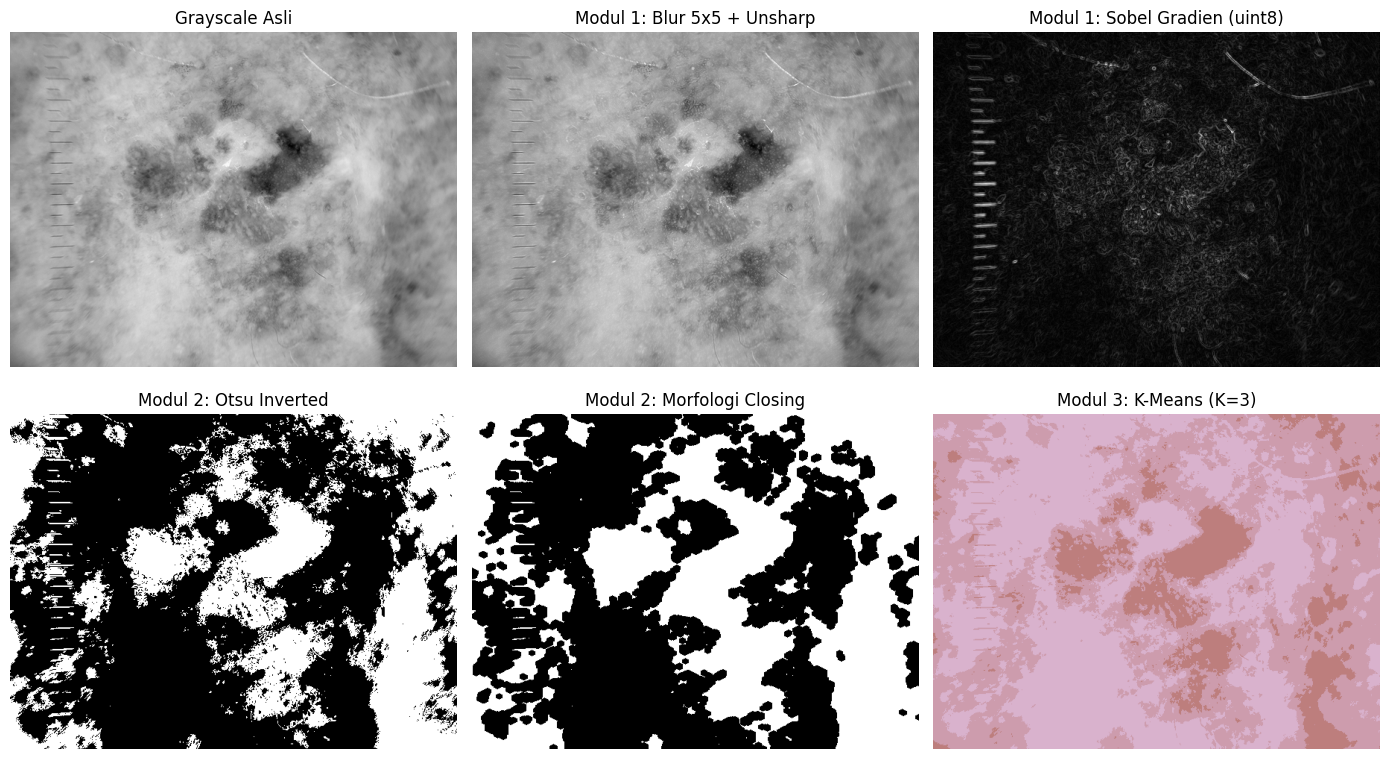


--- Modul 4: Membagi Dataset & Preprocessing ---
Found 8012 validated image filenames belonging to 7 classes.
Found 2003 validated image filenames belonging to 7 classes.
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- Melatih Model EfficientNetB0 ---
Epoch 1/3
251/251 ━━━━━━━━━━━━━━━━━━━━ 830s 3s/step - accuracy: 0.6682 - loss: 1.1609 - val_accuracy: 0.6695 - val_loss: 1.1379
Epoch 2/3
251/251 ━━━━━━━━━━━━━━━━━━━━ 826s 3s/step - accuracy: 0.6695 - loss: 1.1537 - val_accuracy: 0.6695 - val_loss: 1.1386
Epoch 3/3
251/251 ━━━━━━━━━━━━━━━━━━━━ 811s 3s/step - accuracy: 0.6695 - loss: 1.1491 - val_accuracy: 0.6695 - val_loss: 1.1471

--- Mengiterasi Loop Prediksi pada Data Validasi ---
63/63 ━━━━━━━━━━━━━━━━━━━━ 167s 3s/step

================ PERBANDINGAN PREDIKSI VS KEBENARAN ================
No.   | Path File                                     | Kelas Aktual | Kelas Prediksi | Status
------------------------------------------------------------------------------------------
1    

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


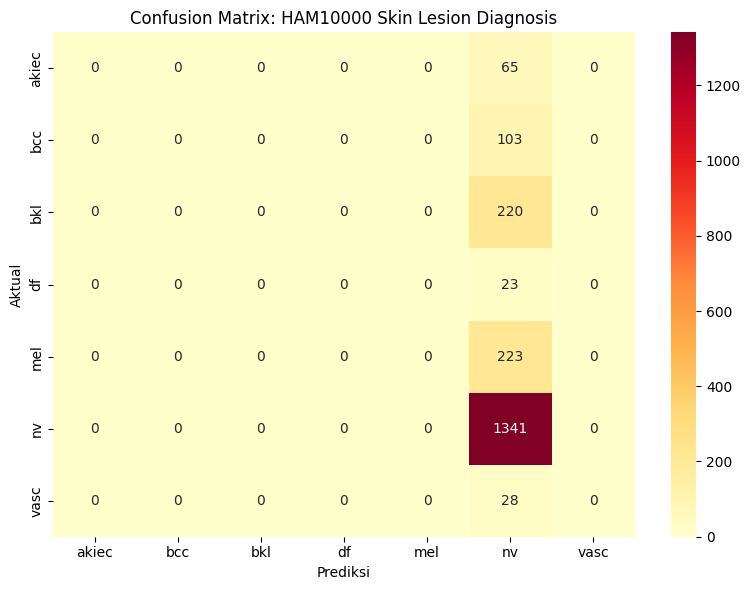

In [ ]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import kagglehub

# =====================================================================
# 0. UNDUH DATASET MENGGUNAKAN KAGGLEHUB & PENGOLAHAN PATH
# =====================================================================
print("--- Mengunduh Dataset HAM10000 via kagglehub ---")
# Mengunduh dataset langsung dari Kaggle
path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
print("Dataset berhasil terunduh di path:", path)

# 1. Deteksi file CSV metadata
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
if not csv_files:
    raise FileNotFoundError(f"File CSV tidak ditemukan di direktori: {path}")

metadata_csv = [f for f in csv_files if "metadata" in os.path.basename(f).lower()]
metadata_csv_path = metadata_csv[0] if metadata_csv else csv_files[0]
print(f"File Metadata CSV: {metadata_csv_path}")

df = pd.read_csv(metadata_csv_path)

# 2. Cari semua gambar (.jpg/.png) di seluruh folder/subfolder dataset
image_files = glob.glob(os.path.join(path, "**", "*.jpg"), recursive=True) + \
              glob.glob(os.path.join(path, "**", "*.jpeg"), recursive=True) + \
              glob.glob(os.path.join(path, "**", "*.png"), recursive=True)

if not image_files:
    raise FileNotFoundError("Tidak ada gambar yang ditemukan dalam folder dataset.")

# Buat pemetaan ID gambar ke file path fisiknya
image_map = {os.path.splitext(os.path.basename(f))[0]: f for f in image_files}

# Tautkan path gambar ke DataFrame
df['file_path'] = df['image_id'].map(image_map)
df = df.dropna(subset=['file_path']).reset_index(drop=True)

# Gunakan kolom diagnosis 'dx' sebagai target kelas
df['class_str'] = df['dx'].astype(str)

print(f"Total gambar valid: {len(df)}")
sample_img_path = df['file_path'].iloc[0]
print(f"Sampel citra untuk Modul 1-3: {sample_img_path}\n")


# =====================================================================
# MODUL 1: Gaussian Blur 5x5, Unsharp Masking & Sobel Gradien uint8
# =====================================================================
def modul_1_processing(image_path):
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise ValueError(f"Gagal memuat citra: {image_path}")

    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # 1. Reduksi noise tekstur rambut halus dengan Gaussian blur 5x5
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # 2. Penambahan matriks detail (Unsharp Masking)
    detail = cv2.subtract(gray, blurred)
    sharpened = cv2.addWeighted(gray, 1.0, detail, 1.5, 0)

    # 3. Magnitudo Sobel sumbu X dan Y, konversi ke uint8
    sobel_x = cv2.Sobel(sharpened, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(sharpened, cv2.CV_64F, 0, 1, ksize=3)
    sobel_mag = cv2.magnitude(sobel_x, sobel_y)

    sobel_uint8 = cv2.normalize(sobel_mag, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

    return gray, sharpened, sobel_uint8


# =====================================================================
# MODUL 2: Otsu Thresholding & Morfologi Closing
# =====================================================================
def modul_2_processing(sharpened_img):
    # 1. Thresholding Otsu Inverted (lesi pekat jadi putih, kulit jadi hitam)
    _, otsu_thresh = cv2.threshold(sharpened_img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # 2. Operasi Morfologi Closing untuk menutup rongga/lubang piksel palsu
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    clean_mask = cv2.morphologyEx(otsu_thresh, cv2.MORPH_CLOSE, kernel, iterations=2)

    return otsu_thresh, clean_mask


# =====================================================================
# MODUL 3: K-Means Color Segmentation (K=3)
# =====================================================================
def modul_3_processing(image_path):
    img_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # 1. Reshape ke matriks 2D float32
    pixel_values = img_rgb.reshape((-1, 3))
    pixel_values = np.float32(pixel_values)

    # 2. K-Means dengan K=3 (Kulit terang, cokelat muda, inti melanoma)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    k = 3

    _, labels, centers = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

    centers = np.uint8(centers)
    segmented_data = centers[labels.flatten()]
    segmented_image = segmented_data.reshape(img_rgb.shape)

    return segmented_image


# =====================================================================
# MODUL 4: Training EfficientNetB0 & Loop Prediksi Validation
# =====================================================================
def modul_4_train_and_eval(df, img_size=(224, 224), batch_size=32, epochs=3):
    print("\n--- Modul 4: Membagi Dataset & Preprocessing ---")

    # Split Stratified
    train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['class_str'])

    datagen = ImageDataGenerator(rescale=1./255)

    train_gen = datagen.flow_from_dataframe(
        dataframe=train_df,
        x_col='file_path',
        y_col='class_str',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=True
    )

    val_gen = datagen.flow_from_dataframe(
        dataframe=val_df,
        x_col='file_path',
        y_col='class_str',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=False
    )

    num_classes = len(train_df['class_str'].unique())

    # Arsitektur EfficientNetB0
    base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(img_size[0], img_size[1], 3))
    base_model.trainable = False

    inputs = layers.Input(shape=(img_size[0], img_size[1], 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    print("\n--- Melatih Model EfficientNetB0 ---")
    model.fit(train_gen, validation_data=val_gen, epochs=epochs)

    # Iterasi Loop Prediksi pada Data Validasi
    print("\n--- Mengiterasi Loop Prediksi pada Data Validasi ---")
    val_gen.reset()
    y_pred_probs = model.predict(val_gen)
    y_pred_indices = np.argmax(y_pred_probs, axis=1)
    y_true_indices = val_gen.classes

    # Pemetaan Indeks ke Label Kelas
    labels_map = {v: k for k, v in val_gen.class_indices.items()}
    class_names = [labels_map[i] for i in range(num_classes)]

    # Cetak Perbandingan Prediksi vs Kebenaran
    print("\n================ PERBANDINGAN PREDIKSI VS KEBENARAN ================")
    print(f"{'No.':<5} | {'Path File':<45} | {'Kelas Aktual':<12} | {'Kelas Prediksi':<12} | {'Status'}")
    print("-" * 90)

    for idx in range(min(10, len(val_df))):
        file_name = os.path.basename(val_df['file_path'].iloc[idx])
        actual_label = labels_map[y_true_indices[idx]]
        pred_label = labels_map[y_pred_indices[idx]]
        status = "MATCH" if actual_label == pred_label else "MISMATCH"
        print(f"{idx+1:<5} | {file_name:<45} | {actual_label:<12} | {pred_label:<12} | {status}")

    print("\n================ CLASSIFICATION REPORT ================")
    print(classification_report(y_true_indices, y_pred_indices, target_names=class_names))

    # Heatmap Confusion Matrix
    cm = confusion_matrix(y_true_indices, y_pred_indices)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='YlOrRd', xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix: HAM10000 Skin Lesion Diagnosis')
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.tight_layout()
    plt.show()


# =====================================================================
# EKSEKUSI PIPELINE
# =====================================================================
if __name__ == "__main__":
    # Jalankan Modul 1, 2, dan 3
    gray_img, sharpened_img, sobel_uint8 = modul_1_processing(sample_img_path)
    otsu_thresh, clean_mask = modul_2_processing(sharpened_img)
    kmeans_segmented = modul_3_processing(sample_img_path)

    # Visualisasi Hasil Pemrosesan Citra
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes[0, 0].imshow(gray_img, cmap='gray')
    axes[0, 0].set_title('Grayscale Asli')

    axes[0, 1].imshow(sharpened_img, cmap='gray')
    axes[0, 1].set_title('Modul 1: Blur 5x5 + Unsharp')

    axes[0, 2].imshow(sobel_uint8, cmap='gray')
    axes[0, 2].set_title('Modul 1: Sobel Gradien (uint8)')

    axes[1, 0].imshow(otsu_thresh, cmap='gray')
    axes[1, 0].set_title('Modul 2: Otsu Inverted')

    axes[1, 1].imshow(clean_mask, cmap='gray')
    axes[1, 1].set_title('Modul 2: Morfologi Closing')

    axes[1, 2].imshow(kmeans_segmented)
    axes[1, 2].set_title('Modul 3: K-Means (K=3)')

    for ax in axes.ravel():
        ax.axis('off')
    plt.tight_layout()
    plt.show()

    # Jalankan Modul 4 (Training Model & Evaluasi Loop Prediksi)
    modul_4_train_and_eval(df, epochs=3)